In [ ]:
!pip install requests geopy osmnx -q  # osmnx solo si MODO_DISTANCIA='osmnx'


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.4/104.4 kB 5.3 MB/s eta 0:00:00


In [ ]:
import os, io, time, math, json, unicodedata, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore')

# ─────────────── CONFIG (igual que el notebook de conteos) ───────────────
RUTA_PROYECTOS  = 'proyectos_solo_ok.xlsx'
SCOPE           = 'LIMA'            # 'LIMA' (departamento) | 'NACIONAL'
RADIO_OSM_POI_M = 1000
POI_EXTRAER     = ['Bus', 'Primaria', 'Universitaria', 'Hospitales',
                   'Alimentacion', 'Tienda', 'EspaciosPublicos', 'Farmacias']

# Distancia: geodésica WGS84 (recomendada) u OSMnx caminando (exacta pero lenta)
MODO_DISTANCIA     = 'geodesica'   # 'geodesica' (elipsoide WGS84, Karney) | 'osmnx' (peatonal real)
FACTOR_TORTUOSIDAD = 1.0           # 1.0 = geodésica pura; súbelo (p.ej. 1.35) para aproximar caminata

CHECKPOINT_DIST = 'osm_distancias_long_checkpoint.csv'
CHECKPOINT_IDS  = 'osm_distancias_procesados.csv'
DELAY_OSM       = 0.3
print('Config lista. Categorías:', POI_EXTRAER, '| distancia:', MODO_DISTANCIA)


Config lista. Categorías: ['Bus', 'Primaria', 'Universitaria', 'Hospitales', 'Alimentacion', 'Tienda', 'EspaciosPublicos', 'Farmacias'] | distancia: geodesica


## 1 · Carga y filtro de proyectos (departamento de Lima)

In [ ]:
def norm_dist(s):
    if pd.isna(s): return s
    s=str(s).strip().upper()
    s=''.join(c for c in unicodedata.normalize('NFD',s) if unicodedata.category(c)!='Mn')
    return ' '.join(s.split())

df = pd.read_excel(RUTA_PROYECTOS)
df['id_proyecto']   = np.arange(1, len(df)+1)
df['NombreProyecto']= df['PROYECTO'].astype(str)
df['Distrito']      = df['DISTRITO'].astype(str)
df['Distrito_key']  = df['Distrito'].map(norm_dist)
df['LATITUD_Y']     = pd.to_numeric(df['LATITUD'], errors='coerce')
df['LONGITUD_X']    = pd.to_numeric(df['LONGITUD'], errors='coerce')
df['Depto_key']     = df['DEPARTAMENTO'].map(norm_dist)
if SCOPE=='LIMA':
    df = df[df['Depto_key']=='LIMA'].copy()
df = df.dropna(subset=['LATITUD_Y','LONGITUD_X']).reset_index(drop=True)
print('Proyectos:', len(df), '| distritos:', df['Distrito_key'].nunique())
df[['id_proyecto','NombreProyecto','Distrito','LATITUD_Y','LONGITUD_X']].head()


Proyectos: 1910 | distritos: 42


,id_proyecto,NombreProyecto,Distrito,LATITUD_Y,LONGITUD_X
0,3,RESIDENCIAL LOS PINOS II,LIMA,-12.154461,-76.991191
1,4,Villa Jacaranda- Torre 2,COMAS,-11.931199,-77.060302
2,5,SAUCES,CHORRILLOS,-12.186711,-76.992397
3,9,ALAMEDA DEL SUR,CHORRILLOS,-12.197160,-77.011601
4,11,HUIRACOCHA,JESUS MARIA,-12.079963,-77.050730


## 2 · Extracción de coordenadas de POIs (OSM) y cálculo de distancias

Una sola petición Overpass por proyecto (union de tags + `out center`). Cada elemento se **clasifica por sus tags** en una de las 8 categorías y se calcula su distancia al proyecto.

In [ ]:
# ── 2.1 Filtros OSM por categoría (nodo/way) y clasificador por tags ──
OSM_FILTERS = {
    'Bus':            [('highway','bus_stop'), ('amenity','bus_station')],
    'Primaria':       [('amenity','school')],
    'Universitaria':  [('amenity','university'), ('amenity','college')],
    'Hospitales':     [('amenity','hospital'), ('amenity','clinic')],
    'Alimentacion':   [('amenity','restaurant'), ('amenity','cafe'),
                       ('amenity','fast_food'), ('amenity','food_court')],
    'Tienda':         [('shop','convenience'), ('shop','supermarket')],
    'EspaciosPublicos':[('leisure','park'), ('leisure','playground'), ('place','square')],
    'Farmacias':      [('amenity','pharmacy')],
}
assert all(c in OSM_FILTERS for c in POI_EXTRAER), 'Falta un filtro en OSM_FILTERS'

def clasificar(tags):
    """Devuelve la lista de categorías (de POI_EXTRAER) que matchea un elemento."""
    cats = []
    for cat in POI_EXTRAER:
        for k, v in OSM_FILTERS[cat]:
            if tags.get(k) == v:
                cats.append(cat); break
    return cats

def _union_query(lat, lon, radio_m, timeout=90):
    partes = [f'[out:json][timeout:{timeout}];', '(']
    for cat in POI_EXTRAER:
        for k, v in OSM_FILTERS[cat]:
            partes.append(f'node["{k}"="{v}"](around:{radio_m},{lat},{lon});')
            partes.append(f'way["{k}"="{v}"](around:{radio_m},{lat},{lon});')
    partes.append(');')
    partes.append('out center;')
    return '\n'.join(partes)


In [ ]:
# ── 2.2 Cliente Overpass + distancia ──
import requests
OVERPASS_ENDPOINTS = [
    'https://overpass-api.de/api/interpreter',
    'https://overpass.kumi.systems/api/interpreter',
    'https://maps.mail.ru/osm/tools/overpass/api/interpreter',
]
_HEADERS = {'Content-Type': 'application/x-www-form-urlencoded'}

def _post_overpass(query, timeout=90):
    body = 'data=' + requests.utils.quote(query)
    for url in OVERPASS_ENDPOINTS:
        try:
            r = requests.post(url, data=body, headers=_HEADERS, timeout=timeout)
            if r.status_code == 200: return r.json()
            if r.status_code == 429:
                time.sleep(8)
                r2 = requests.post(url, data=body, headers=_HEADERS, timeout=timeout)
                if r2.status_code == 200: return r2.json()
        except Exception:
            continue
    return None

def haversine_m(lat1, lon1, lat2, lon2):
    R=6371000.0
    p1,p2=math.radians(lat1),math.radians(lat2)
    dp=math.radians(lat2-lat1); dl=math.radians(lon2-lon1)
    a=math.sin(dp/2)**2+math.cos(p1)*math.cos(p2)*math.sin(dl/2)**2
    return R*2*math.atan2(math.sqrt(a),math.sqrt(1-a))

# Distancia geodésica (elipsoide WGS84, algoritmo de Karney) vía geopy
try:
    from geopy.distance import geodesic as _geodesic
    def geodesica_m(lat0, lon0, lat1, lon1):
        return _geodesic((lat0,lon0),(lat1,lon1)).meters
except Exception:
    geodesica_m = haversine_m   # respaldo esférico si geopy no está disponible

# OSMnx opcional (distancia peatonal real por grafo)
_G_CACHE = {}
def _distancia(lat0, lon0, lat1, lon1):
    if MODO_DISTANCIA == 'osmnx':
        try:
            import osmnx as ox, networkx as nx
            key=(round(lat0,3),round(lon0,3))
            if key not in _G_CACHE:
                _G_CACHE[key]=ox.graph_from_point((lat0,lon0),dist=1500,network_type='walk')
            G=_G_CACHE[key]
            n0=ox.distance.nearest_nodes(G,lon0,lat0); n1=ox.distance.nearest_nodes(G,lon1,lat1)
            return nx.shortest_path_length(G,n0,n1,weight='length')
        except Exception:
            pass  # cae a geodésica
    return geodesica_m(lat0, lon0, lat1, lon1) * FACTOR_TORTUOSIDAD

def distancias_proyecto(lat, lon, radio_m):
    """Lista de (categoria, dist_m) para todos los POIs del proyecto. None si falla API."""
    data = _post_overpass(_union_query(lat, lon, radio_m), timeout=90)
    if data is None:
        return None
    filas = []
    for el in data.get('elements', []):
        tags = el.get('tags', {}) or {}
        cats = clasificar(tags)
        if not cats:
            continue
        if el.get('type')=='node':
            plat, plon = el.get('lat'), el.get('lon')
        else:
            c = el.get('center') or {}
            plat, plon = c.get('lat'), c.get('lon')
        if plat is None or plon is None:
            continue
        d = round(_distancia(lat, lon, plat, plon), 1)
        for cat in cats:
            filas.append((cat, d))
    return filas


In [ ]:
# ── 2.3 Batch con checkpoint (REQUIERE INTERNET) ──
if os.path.exists(CHECKPOINT_IDS):
    procesados = set(pd.read_csv(CHECKPOINT_IDS)['id_proyecto'].tolist())
    long_rows  = pd.read_csv(CHECKPOINT_DIST).values.tolist() if os.path.exists(CHECKPOINT_DIST) else []
    print(f'Checkpoint: {len(procesados)} proyectos ya procesados, {len(long_rows)} filas.')
else:
    procesados, long_rows = set(), []
    print('Extracción desde cero.')

pend = [i for i in df.index if df.at[i,'id_proyecto'] not in procesados]
print('Pendientes:', len(pend))

t0=time.time(); fallos=0
for n, idx in enumerate(pend):
    pid = df.at[idx,'id_proyecto']
    lat, lon = df.at[idx,'LATITUD_Y'], df.at[idx,'LONGITUD_X']
    res = distancias_proyecto(lat, lon, RADIO_OSM_POI_M)
    if res is None:
        fallos += 1
        if fallos>=6: print('🛑 6 fallos seguidos, guardo y aborto.'); break
        time.sleep(2); continue
    fallos=0
    for cat, d in res:
        long_rows.append([pid, cat, d])
    procesados.add(pid)
    time.sleep(DELAY_OSM)
    if (n+1)%50==0:
        pd.DataFrame(long_rows, columns=['id_proyecto','categoria','dist_m']).to_csv(CHECKPOINT_DIST,index=False)
        pd.DataFrame({'id_proyecto':list(procesados)}).to_csv(CHECKPOINT_IDS,index=False)
        vel=(n+1)/(time.time()-t0); eta=(len(pend)-(n+1))/vel/60
        print(f'  [{n+1}/{len(pend)}] {vel:.1f} proy/s | ETA ~{eta:.1f} min | filas {len(long_rows)}')

dist_long = pd.DataFrame(long_rows, columns=['id_proyecto','categoria','dist_m'])
dist_long.to_csv(CHECKPOINT_DIST,index=False)
pd.DataFrame({'id_proyecto':list(procesados)}).to_csv(CHECKPOINT_IDS,index=False)
print('Listo. Filas de distancia:', len(dist_long))
dist_long.head()


Extracción desde cero.
Pendientes: 1910
  [50/1910] 0.1 proy/s | ETA ~399.6 min | filas 8068
  [100/1910] 0.1 proy/s | ETA ~418.6 min | filas 16276
  [150/1910] 0.1 proy/s | ETA ~435.9 min | filas 26307
  [200/1910] 0.1 proy/s | ETA ~416.3 min | filas 36226
  [250/1910] 0.1 proy/s | ETA ~409.7 min | filas 45280
  [300/1910] 0.1 proy/s | ETA ~424.9 min | filas 52731
  [350/1910] 0.1 proy/s | ETA ~406.9 min | filas 60944
  [400/1910] 0.1 proy/s | ETA ~385.7 min | filas 69717
  [450/1910] 0.1 proy/s | ETA ~378.0 min | filas 78757
  [500/1910] 0.1 proy/s | ETA ~382.9 min | filas 85827
  [550/1910] 0.1 proy/s | ETA ~375.5 min | filas 94881
  [600/1910] 0.1 proy/s | ETA ~358.1 min | filas 102341
  [650/1910] 0.1 proy/s | ETA ~343.5 min | filas 113168
  [700/1910] 0.1 proy/s | ETA ~324.8 min | filas 122548
  [750/1910] 0.1 proy/s | ETA ~316.5 min | filas 132198
  [800/1910] 0.1 proy/s | ETA ~300.6 min | filas 141950
  [850/1910] 0.1 proy/s | ETA ~285.2 min | filas 149905
  [900/1910] 0.1 proy

,id_proyecto,categoria,dist_m
0,3,Bus,907.7
1,3,Alimentacion,992.1
2,3,Farmacias,554.3
3,3,Alimentacion,561.5
4,3,Alimentacion,401.9


## 3 · Tabla ancha por proyecto (features para el modelo prescriptivo)

Por proyecto y categoría: distancia **mínima** (POI más cercano), **media**, **conteo**, y **bandas de caminata** (≤400 m ≈ 5 min, ≤800 m ≈ 10 min).

In [ ]:
BANDAS = [400, 800, 1000]   # metros (aprox. 5, 10, 12-15 min caminando)

def features_por_proyecto(dist_long, df_base, categorias):
    base = df_base[['id_proyecto']].copy()
    for cat in categorias:
        sub = dist_long[dist_long['categoria']==cat]
        agg = sub.groupby('id_proyecto')['dist_m'].agg(['min','mean','count'])
        base = base.merge(agg.rename(columns={
            'min':f'dist_min_{cat}','mean':f'dist_mean_{cat}','count':f'n_{cat}'
        }), on='id_proyecto', how='left')
        for b in BANDAS:
            cnt = sub[sub['dist_m']<=b].groupby('id_proyecto').size().rename(f'n_{cat}_le{b}')
            base = base.merge(cnt, on='id_proyecto', how='left')
    # Sin POI en radio → conteos 0; distancias → NaN (se marcan como radio máximo caminando)
    for c in base.columns:
        if c.startswith('n_'):   base[c]=base[c].fillna(0).astype(int)
    for c in base.columns:
        if c.startswith('dist_'): base[c]=base[c].fillna(RADIO_OSM_POI_M*FACTOR_TORTUOSIDAD)
    return base

feat = features_por_proyecto(dist_long, df, POI_EXTRAER)
print('Tabla ancha:', feat.shape)
feat.head()


Tabla ancha: (1910, 49)


,id_proyecto,dist_min_Bus,dist_mean_Bus,n_Bus,n_Bus_le400,n_Bus_le800,n_Bus_le1000,dist_min_Primaria,dist_mean_Primaria,n_Primaria,...,n_EspaciosPublicos,n_EspaciosPublicos_le400,n_EspaciosPublicos_le800,n_EspaciosPublicos_le1000,dist_min_Farmacias,dist_mean_Farmacias,n_Farmacias,n_Farmacias_le400,n_Farmacias_le800,n_Farmacias_le1000
0,3,201.1,702.580952,21,3,12,21,292.1,677.309524,21,...,65,10,42,60,137.5,731.578261,23,1,13,23
1,4,602.7,733.566667,12,0,6,12,100.7,705.482500,40,...,67,9,44,63,470.0,741.282353,17,0,11,17
2,5,280.6,660.264286,14,2,8,14,85.6,647.538710,31,...,29,12,23,28,275.6,741.772727,11,1,4,11
3,9,19.1,486.209091,11,5,9,11,74.9,727.014286,42,...,36,6,23,36,214.4,741.769231,13,4,4,13
4,11,575.1,719.562500,16,0,11,16,312.9,713.825532,47,...,55,8,27,46,125.8,551.911538,26,6,25,26


## 4 · Distribución de distancias

In [ ]:
import matplotlib.pyplot as plt
resumen = (dist_long.groupby('categoria')['dist_m']
           .agg(n='count', mediana='median',
                p25=lambda s:s.quantile(.25), p75=lambda s:s.quantile(.75),
                media='mean', maximo='max').round(1)
           .reindex(POI_EXTRAER))
resumen['%<=400m'] = (dist_long.assign(f=dist_long.dist_m<=400)
                      .groupby('categoria')['f'].mean().reindex(POI_EXTRAER)*100).round(1)
resumen['%<=800m'] = (dist_long.assign(f=dist_long.dist_m<=800)
                      .groupby('categoria')['f'].mean().reindex(POI_EXTRAER)*100).round(1)
print('Resumen de distribución de distancias (m):')
resumen


Resumen de distribución de distancias (m):


,n,mediana,p25,p75,media,maximo,%<=400m,%<=800m
categoria,,,,,,,,
Bus,25207,711.1,541.5,837.4,667.7,1017.9,15.3,61.9
Primaria,64609,723.1,516.2,857.6,678.1,1210.6,13.8,62.0
Universitaria,9386,747.6,497.3,918.6,701.0,1176.3,12.9,57.7
Hospitales,12761,723.0,552.6,880.5,691.6,1201.8,12.4,62.6
Alimentacion,93940,708.3,533.4,850.2,668.3,1055.2,14.9,66.9
Tienda,21232,674.6,506.2,868.9,650.0,1059.4,18.1,63.7
EspaciosPublicos,87125,686.3,507.1,875.2,668.8,1500.2,15.7,64.5
Farmacias,32749,730.1,570.9,857.7,692.6,1004.8,9.8,65.0


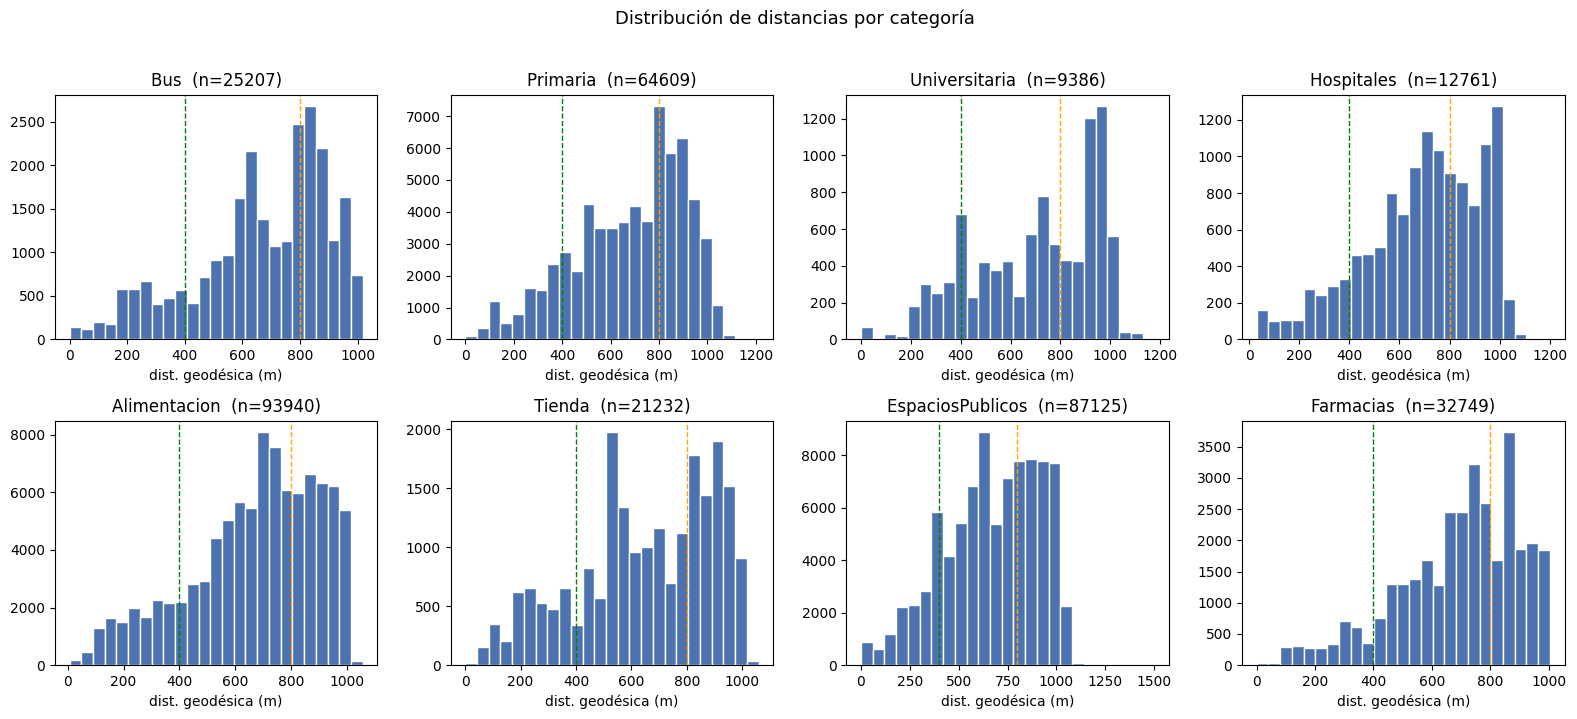

In [ ]:
# ── 4.1 Histogramas por categoría ──
cats = POI_EXTRAER
fig, axes = plt.subplots(2, 4, figsize=(16,7)); axes=axes.ravel()
for i, cat in enumerate(cats):
    s = dist_long.loc[dist_long['categoria']==cat, 'dist_m']
    axes[i].hist(s, bins=25, color='#4C72B0', edgecolor='white')
    axes[i].axvline(400, color='green', ls='--', lw=1)
    axes[i].axvline(800, color='orange', ls='--', lw=1)
    axes[i].set_title(f'{cat}  (n={len(s)})'); axes[i].set_xlabel('dist. geodésica (m)')
plt.suptitle('Distribución de distancias por categoría', y=1.02, fontsize=13)
plt.tight_layout(); plt.show()


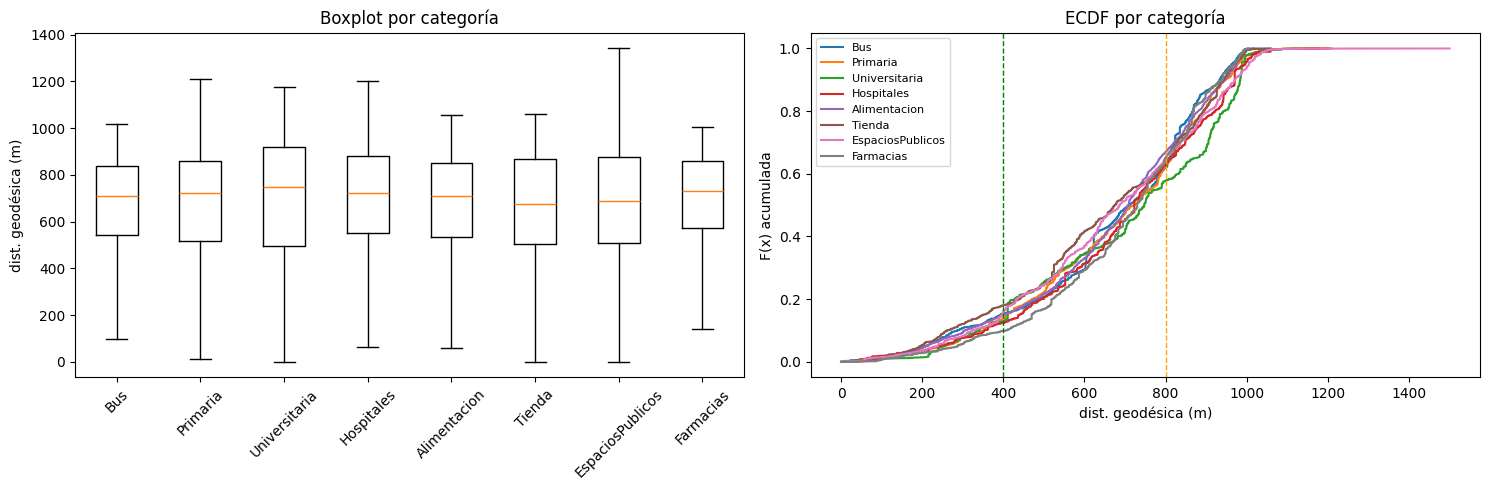

In [ ]:
# ── 4.2 Boxplot comparativo + ECDF ──
fig, ax = plt.subplots(1, 2, figsize=(15,5))
data = [dist_long.loc[dist_long['categoria']==c,'dist_m'].values for c in cats]
ax[0].boxplot(data, labels=cats, showfliers=False)
ax[0].set_ylabel('dist. geodésica (m)'); ax[0].set_title('Boxplot por categoría')
ax[0].tick_params(axis='x', rotation=45)
for c in cats:
    s=np.sort(dist_long.loc[dist_long['categoria']==c,'dist_m'].values)
    if len(s): ax[1].plot(s, np.linspace(0,1,len(s)), label=c)
ax[1].axvline(400,color='green',ls='--',lw=1); ax[1].axvline(800,color='orange',ls='--',lw=1)
ax[1].set_xlabel('dist. geodésica (m)'); ax[1].set_ylabel('F(x) acumulada')
ax[1].set_title('ECDF por categoría'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


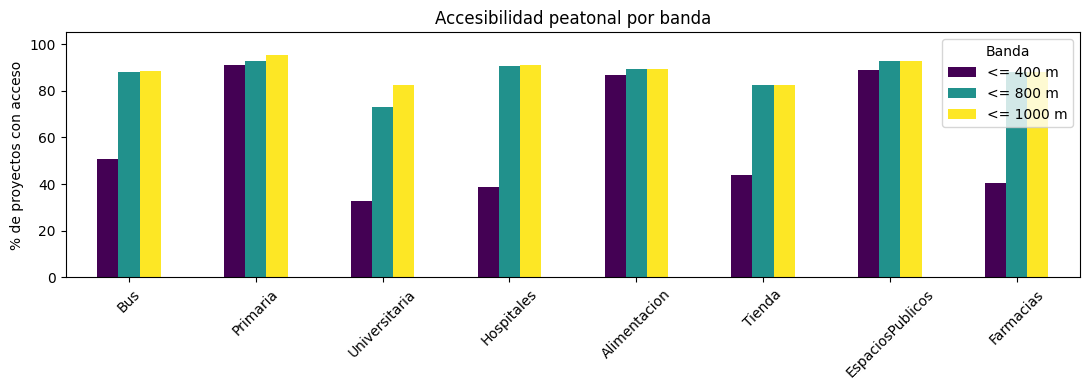

,<= 400 m,<= 800 m,<= 1000 m
Bus,50.8,88.2,88.5
Primaria,91.0,92.7,95.2
Universitaria,32.9,72.9,82.4
Hospitales,38.8,90.5,90.8
Alimentacion,86.9,89.2,89.2
Tienda,44.0,82.5,82.5
EspaciosPublicos,88.8,92.8,92.9
Farmacias,40.3,88.2,88.2


In [ ]:
# ── 4.3 Accesibilidad: % de proyectos con al menos 1 POI dentro de cada banda ──
acc = pd.DataFrame(index=cats)
for b in BANDAS:
    acc[f'<= {b} m'] = [ (feat[f'n_{c}_le{b}']>0).mean()*100 for c in cats ]
acc = acc.round(1)
acc.plot.bar(figsize=(11,4), colormap='viridis')
plt.ylabel('% de proyectos con acceso'); plt.title('Accesibilidad peatonal por banda')
plt.xticks(rotation=45); plt.ylim(0,105); plt.legend(title='Banda'); plt.tight_layout(); plt.show()
acc


## 5 · Exportación (insumos para la Fase 3)

In [ ]:
dist_long.to_csv('distancias_long.csv', index=False, encoding='utf-8-sig')
feat.to_csv('distancias_por_proyecto.csv', index=False, encoding='utf-8-sig')
resumen.to_csv('resumen_distribucion_distancias.csv', encoding='utf-8-sig')
print('✅ Exportado:')
print('   • distancias_long.csv               (proyecto, categoría, dist_m) — para distribuciones')
print('   • distancias_por_proyecto.csv       (dist_min/mean/n/bandas) — features prescriptivas')
print('   • resumen_distribucion_distancias.csv')
print(f'\nProyectos: {feat.shape[0]} | columnas de features: {feat.shape[1]-1}')


✅ Exportado:
   • distancias_long.csv               (proyecto, categoría, dist_m) — para distribuciones
   • distancias_por_proyecto.csv       (dist_min/mean/n/bandas) — features prescriptivas
   • resumen_distribucion_distancias.csv

Proyectos: 1910 | columnas de features: 48


## 6 · Unión con la Fase 2 → dataset único para la Fase 3

Une las distancias (`distancias_por_proyecto.csv`) con el dataset de la Fase 2 (`FinalEmbeddings_fase2.csv`, con conteos + score + etiqueta) por `id_proyecto`. Ambos notebooks asignan `id_proyecto` sobre la base completa antes de filtrar, así que la clave coincide. Incluye verificación cruzada conteos-vs-distancias y exporta `FinalEmbeddings_fase3.csv`.

In [ ]:
RUTA_FASE2 = 'FinalEmbeddings_fase2.csv'   # salida del notebook de conteos (mismo Colab)

if not os.path.exists(RUTA_FASE2):
    print(f'⚠️  No encuentro {RUTA_FASE2}. Súbelo o corre antes el notebook de la Fase 2.')
else:
    base2 = pd.read_csv(RUTA_FASE2, sep=';')
    print('Fase 2:', base2.shape, '| Distancias:', feat.shape)

    # ── Unión por id_proyecto ──
    merged = base2.merge(feat, on='id_proyecto', how='left')
    faltan = merged['dist_min_'+POI_EXTRAER[0]].isna().sum()
    print(f'Proyectos sin distancias tras el merge: {faltan}')

    # ── Verificación cruzada: conteo Fase 2 (col '{cat}') vs conteo distancias ('n_{cat}') ──
    print('\nVerificación conteos (Fase 2)  vs  n_(distancias):')
    for cat in POI_EXTRAER:
        if cat in merged and f'n_{cat}' in merged:
            a, b = merged[cat].fillna(0), merged[f'n_{cat}'].fillna(0)
            r = np.corrcoef(a, b)[0,1] if a.std()>0 and b.std()>0 else float('nan')
            print(f'  {cat:16s}  corr={r:5.2f}  | dif. media abs={np.abs(a-b).mean():.2f}')

    # ── Exportar dataset único ──
    merged.to_csv('FinalEmbeddings_fase3.csv', sep=';', index=False, encoding='utf-8-sig')
    print(f'\n✅ FinalEmbeddings_fase3.csv exportado: {merged.shape[0]} filas × {merged.shape[1]} columnas')
    print('   (conteos + distancias + score + etiqueta → listo para el modelo prescriptivo)')
    merged.head()


⚠️  No encuentro FinalEmbeddings_fase2.csv. Súbelo o corre antes el notebook de la Fase 2.


---
### Notas
- **Distancia:** por defecto **geodésica** (elipsoide WGS84, algoritmo de Karney, vía `geopy`) — distancia real en línea sobre la superficie terrestre. Con `FACTOR_TORTUOSIDAD>1` (p. ej. 1.35) la aproximas a caminata; con `MODO_DISTANCIA='osmnx'` obtienes distancia peatonal real por grafo (más exacta, mucho más lenta).
- **`dist_min_{cat}`** (POI más cercano por categoría) es la variable clave para el modelo prescriptivo; si no hay POI en el radio se imputa `RADIO × FACTOR_TORTUOSIDAD` como "peor caso alcanzable".
- **Coherencia:** `n_{cat}` de este notebook debe coincidir (±) con los conteos del notebook de la Fase 2; sirve de verificación cruzada.
- **Bandas 400/800/1000 m** (distancia geodésica) ≈ 5/10/~13 min caminando aprox., alineadas al concepto de ciudad de 15 minutos.
